<a href="https://colab.research.google.com/github/rudraish/Movie_Recommendation_model/blob/main/movie_recommendation_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("/content/mymoviedb.csv", engine="python")

In [4]:
df.head()

,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original_Language,Genre,Poster_Url
0,2021-12-15,Spider-Man: No Way Home,Peter Parker is unmasked and no longer able to...,5083.954,8940,8.3,en,"Action, Adventure, Science Fiction",https://image.tmdb.org/t/p/original/1g0dhYtq4i...
1,2022-03-01,The Batman,"In his second year of fighting crime, Batman u...",3827.658,1151,8.1,en,"Crime, Mystery, Thriller",https://image.tmdb.org/t/p/original/74xTEgt7R3...
2,2022-02-25,No Exit,Stranded at a rest stop in the mountains durin...,2618.087,122,6.3,en,Thriller,https://image.tmdb.org/t/p/original/vDHsLnOWKl...
3,2021-11-24,Encanto,"The tale of an extraordinary family, the Madri...",2402.201,5076,7.7,en,"Animation, Comedy, Family, Fantasy",https://image.tmdb.org/t/p/original/4j0PNHkMr5...
4,2021-12-22,The King's Man,As a collection of history's worst tyrants and...,1895.511,1793,7.0,en,"Action, Adventure, Thriller, War",https://image.tmdb.org/t/p/original/aq4Pwv5Xeu...


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9837 entries, 0 to 9836
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Release_Date       9837 non-null   object 
 1   Title              9828 non-null   object 
 2   Overview           9828 non-null   object 
 3   Popularity         9827 non-null   float64
 4   Vote_Count         9827 non-null   object 
 5   Vote_Average       9827 non-null   object 
 6   Original_Language  9827 non-null   object 
 7   Genre              9826 non-null   object 
 8   Poster_Url         9826 non-null   object 
dtypes: float64(1), object(8)
memory usage: 691.8+ KB


In [6]:
df['Release_Date'] = pd.to_datetime(df['Release_Date'], errors='coerce')

print(df['Release_Date'].dtypes)

datetime64[ns]


In [7]:
df['Release_Date'] = df['Release_Date'].dt.year

print(df['Release_Date'].dtypes)

float64


In [8]:
df['Vote_Count'] = pd.to_numeric(df['Vote_Count'], errors='coerce')

print(df['Vote_Count'].dtypes)

float64


In [9]:
df

,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original_Language,Genre,Poster_Url
0,2021.0,Spider-Man: No Way Home,Peter Parker is unmasked and no longer able to...,5083.954,8940.0,8.3,en,"Action, Adventure, Science Fiction",https://image.tmdb.org/t/p/original/1g0dhYtq4i...
1,2022.0,The Batman,"In his second year of fighting crime, Batman u...",3827.658,1151.0,8.1,en,"Crime, Mystery, Thriller",https://image.tmdb.org/t/p/original/74xTEgt7R3...
2,2022.0,No Exit,Stranded at a rest stop in the mountains durin...,2618.087,122.0,6.3,en,Thriller,https://image.tmdb.org/t/p/original/vDHsLnOWKl...
3,2021.0,Encanto,"The tale of an extraordinary family, the Madri...",2402.201,5076.0,7.7,en,"Animation, Comedy, Family, Fantasy",https://image.tmdb.org/t/p/original/4j0PNHkMr5...
4,2021.0,The King's Man,As a collection of history's worst tyrants and...,1895.511,1793.0,7.0,en,"Action, Adventure, Thriller, War",https://image.tmdb.org/t/p/original/aq4Pwv5Xeu...
...,...,...,...,...,...,...,...,...,...
9832,1973.0,Badlands,A dramatization of the Starkweather-Fugate kil...,13.357,896.0,7.6,en,"Drama, Crime",https://image.tmdb.org/t/p/original/z81rBzHNgi...
9833,2020.0,Violent Delights,A female vampire falls in love with a man she ...,13.356,8.0,3.5,es,Horror,https://image.tmdb.org/t/p/original/4b6HY7rud6...
9834,2016.0,The Offering,When young and successful reporter Jamie finds...,13.355,94.0,5.0,en,"Mystery, Thriller, Horror",https://image.tmdb.org/t/p/original/h4uMM1wOhz...
9835,2021.0,The United States vs. Billie Holiday,Billie Holiday spent much of her career being ...,13.354,152.0,6.7,en,"Music, Drama, History",https://image.tmdb.org/t/p/original/vEzkxuE2sJ...


In [10]:
# Fill missing values with the most common release date (mode)
most_common_date = df['Release_Date'].mode()
df['Release_Date'] = df['Release_Date'].fillna(most_common_date)


In [11]:
df

,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original_Language,Genre,Poster_Url
0,2021.0,Spider-Man: No Way Home,Peter Parker is unmasked and no longer able to...,5083.954,8940.0,8.3,en,"Action, Adventure, Science Fiction",https://image.tmdb.org/t/p/original/1g0dhYtq4i...
1,2022.0,The Batman,"In his second year of fighting crime, Batman u...",3827.658,1151.0,8.1,en,"Crime, Mystery, Thriller",https://image.tmdb.org/t/p/original/74xTEgt7R3...
2,2022.0,No Exit,Stranded at a rest stop in the mountains durin...,2618.087,122.0,6.3,en,Thriller,https://image.tmdb.org/t/p/original/vDHsLnOWKl...
3,2021.0,Encanto,"The tale of an extraordinary family, the Madri...",2402.201,5076.0,7.7,en,"Animation, Comedy, Family, Fantasy",https://image.tmdb.org/t/p/original/4j0PNHkMr5...
4,2021.0,The King's Man,As a collection of history's worst tyrants and...,1895.511,1793.0,7.0,en,"Action, Adventure, Thriller, War",https://image.tmdb.org/t/p/original/aq4Pwv5Xeu...
...,...,...,...,...,...,...,...,...,...
9832,1973.0,Badlands,A dramatization of the Starkweather-Fugate kil...,13.357,896.0,7.6,en,"Drama, Crime",https://image.tmdb.org/t/p/original/z81rBzHNgi...
9833,2020.0,Violent Delights,A female vampire falls in love with a man she ...,13.356,8.0,3.5,es,Horror,https://image.tmdb.org/t/p/original/4b6HY7rud6...
9834,2016.0,The Offering,When young and successful reporter Jamie finds...,13.355,94.0,5.0,en,"Mystery, Thriller, Horror",https://image.tmdb.org/t/p/original/h4uMM1wOhz...
9835,2021.0,The United States vs. Billie Holiday,Billie Holiday spent much of her career being ...,13.354,152.0,6.7,en,"Music, Drama, History",https://image.tmdb.org/t/p/original/vEzkxuE2sJ...


In [12]:
df.isnull().sum()

,0
Release_Date,10
Title,9
Overview,9
Popularity,10
Vote_Count,11
Vote_Average,10
Original_Language,10
Genre,11
Poster_Url,11


In [13]:
# Inspect non-numeric entries in Vote_Count
non_numeric_votes = df[pd.to_numeric(df['Vote_Count'], errors='coerce').isna()]['Vote_Count'].unique()
print("Unique non-numeric entries in Vote_Count:", non_numeric_votes)

# Inspect non-numeric entries in Vote_Average
non_numeric_averages = df[pd.to_numeric(df['Vote_Average'], errors='coerce').isna()]['Vote_Average'].unique()
print("Unique non-numeric entries in Vote_Average:", non_numeric_averages)

Unique non-numeric entries in Vote_Count: [nan]
Unique non-numeric entries in Vote_Average: [None 'Animation']


In [14]:
# Convert Vote_Count and Vote_Average to numeric types safely
# Invalid values (like 'en' or 'Animation') will become NaN
df['Vote_Count'] = pd.to_numeric(df['Vote_Count'], errors='coerce')
df['Vote_Average'] = pd.to_numeric(df['Vote_Average'], errors='coerce')

# Let's verify the updated data types and count non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9837 entries, 0 to 9836
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Release_Date       9827 non-null   float64
 1   Title              9828 non-null   object 
 2   Overview           9828 non-null   object 
 3   Popularity         9827 non-null   float64
 4   Vote_Count         9826 non-null   float64
 5   Vote_Average       9826 non-null   float64
 6   Original_Language  9827 non-null   object 
 7   Genre              9826 non-null   object 
 8   Poster_Url         9826 non-null   object 
dtypes: float64(4), object(5)
memory usage: 691.8+ KB


##In Python, astype() is a method used in data libraries like pandas and NumPy to convert the data type (dtype) of a DataFrame, Series, or array

In [15]:
# 1. Drop the rows containing NaN values in our target numeric columns
df = df.dropna(subset=['Vote_Count', 'Vote_Average'])

# 2. Cast Vote_Count from float to integer
df['Vote_Count'] = df['Vote_Count'].astype(int)
df['Vote_Average'] = df['Vote_Average'].astype(float)
# 3. Confirm clean structure
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9826 entries, 0 to 9836
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Release_Date       9826 non-null   float64
 1   Title              9826 non-null   object 
 2   Overview           9826 non-null   object 
 3   Popularity         9826 non-null   float64
 4   Vote_Count         9826 non-null   int64  
 5   Vote_Average       9826 non-null   float64
 6   Original_Language  9826 non-null   object 
 7   Genre              9826 non-null   object 
 8   Poster_Url         9826 non-null   object 
dtypes: float64(3), int64(1), object(5)
memory usage: 767.7+ KB


/tmp/ipykernel_7009/2672703067.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Vote_Count'] = df['Vote_Count'].astype(int)
/tmp/ipykernel_7009/2672703067.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Vote_Average'] = df['Vote_Average'].astype(float)


In [16]:
df.head()

,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original_Language,Genre,Poster_Url
0,2021.0,Spider-Man: No Way Home,Peter Parker is unmasked and no longer able to...,5083.954,8940,8.3,en,"Action, Adventure, Science Fiction",https://image.tmdb.org/t/p/original/1g0dhYtq4i...
1,2022.0,The Batman,"In his second year of fighting crime, Batman u...",3827.658,1151,8.1,en,"Crime, Mystery, Thriller",https://image.tmdb.org/t/p/original/74xTEgt7R3...
2,2022.0,No Exit,Stranded at a rest stop in the mountains durin...,2618.087,122,6.3,en,Thriller,https://image.tmdb.org/t/p/original/vDHsLnOWKl...
3,2021.0,Encanto,"The tale of an extraordinary family, the Madri...",2402.201,5076,7.7,en,"Animation, Comedy, Family, Fantasy",https://image.tmdb.org/t/p/original/4j0PNHkMr5...
4,2021.0,The King's Man,As a collection of history's worst tyrants and...,1895.511,1793,7.0,en,"Action, Adventure, Thriller, War",https://image.tmdb.org/t/p/original/aq4Pwv5Xeu...


In [17]:
cols = ['Overview', 'Original_Language', 'Poster_Url']

In [18]:
df.drop(cols, axis=1, inplace=True)
# In pandas, setting inplace=True modifies the original DataFrame or Series directly without needing
# to assign the result to a new variable. By default, pandas methods use inplace=False, which leaves the
# original data untouched and returns a new copy with the changes



/tmp/ipykernel_7009/218361672.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(cols, axis=1, inplace=True)


In [19]:
df.columns

Index(['Release_Date', 'Title', 'Popularity', 'Vote_Count', 'Vote_Average',
       'Genre'],
      dtype='object')

In [20]:
df.head()

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre
0,2021.0,Spider-Man: No Way Home,5083.954,8940,8.3,"Action, Adventure, Science Fiction"
1,2022.0,The Batman,3827.658,1151,8.1,"Crime, Mystery, Thriller"
2,2022.0,No Exit,2618.087,122,6.3,Thriller
3,2021.0,Encanto,2402.201,5076,7.7,"Animation, Comedy, Family, Fantasy"
4,2021.0,The King's Man,1895.511,1793,7.0,"Action, Adventure, Thriller, War"


# df.describe() is a method from the pandas library that generates a quick statistical summary of the data in a DataFrame


###pd.cut() is a function in the Python pandas library used to segment and sort continuous numerical data into discrete intervals (called bins). It is primarily used to convert continuous variables, like exact ages or test scores, into categorical groups, such as age brackets or letter grades.

Categorizing the vote average in 4 different categories ie Popular, Average,  below_average, boaring

In [21]:
labels = ['boring', 'below_average', 'average', 'popular']

In [22]:
def categorize_vote(df, col, labels):

  # edges = [df[cols].min(), df[cols].quantile(0.25), df[cols].quantile(0.5), df[cols].quantile(0.75), df[cols].max()]
  edges = [df[col].describe()['min'],
           df[col].describe()['25%'],
           df[col].describe()['50%'],
           df[col].describe()['75%'],
           df[col].describe()['max']]

  df[col] = pd.cut(df[col], edges, labels=labels, duplicates='drop')
  return df

In [23]:
categorize_vote(df, 'Vote_Average', labels)

/tmp/ipykernel_7009/1443094673.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[col] = pd.cut(df[col], edges, labels=labels, duplicates='drop')


,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre
0,2021.0,Spider-Man: No Way Home,5083.954,8940,popular,"Action, Adventure, Science Fiction"
1,2022.0,The Batman,3827.658,1151,popular,"Crime, Mystery, Thriller"
2,2022.0,No Exit,2618.087,122,below_average,Thriller
3,2021.0,Encanto,2402.201,5076,popular,"Animation, Comedy, Family, Fantasy"
4,2021.0,The King's Man,1895.511,1793,average,"Action, Adventure, Thriller, War"
...,...,...,...,...,...,...
9832,1973.0,Badlands,13.357,896,popular,"Drama, Crime"
9833,2020.0,Violent Delights,13.356,8,boring,Horror
9834,2016.0,The Offering,13.355,94,boring,"Mystery, Thriller, Horror"
9835,2021.0,The United States vs. Billie Holiday,13.354,152,average,"Music, Drama, History"


In [24]:
df['Vote_Average'].unique()

['popular', 'below_average', 'average', 'boring', NaN]
Categories (4, object): ['boring' < 'below_average' < 'average' < 'popular']

In [25]:
df.head()

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre
0,2021.0,Spider-Man: No Way Home,5083.954,8940,popular,"Action, Adventure, Science Fiction"
1,2022.0,The Batman,3827.658,1151,popular,"Crime, Mystery, Thriller"
2,2022.0,No Exit,2618.087,122,below_average,Thriller
3,2021.0,Encanto,2402.201,5076,popular,"Animation, Comedy, Family, Fantasy"
4,2021.0,The King's Man,1895.511,1793,average,"Action, Adventure, Thriller, War"


##.value_counts() is a pandas method that counts how many times each unique value appears in a Series or DataFrame column

In [26]:
df['Vote_Average'].value_counts()

,count
Vote_Average,
boring,2467
popular,2450
average,2411
below_average,2398


In [27]:
df.isna().sum()

,0
Release_Date,0
Title,0
Popularity,0
Vote_Count,0
Vote_Average,100
Genre,0


In [28]:
df['Vote_Average'].isna().sum()

np.int64(100)

##inplace=True so that the original df is also changed rather than creating an internal copy of the dataframe

In [29]:
df.dropna(inplace=True)

/tmp/ipykernel_7009/1422412847.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.dropna(inplace=True)


In [30]:
df['Vote_Average'].isna().sum()

np.int64(0)

###we split genre into a list and then explode our dataframe to have only one genre per row for each movie.

.str.split() is a pandas Series method that breaks each string in a column into a list of smaller substrings based on a specified separator (delimiter).


You can control how .str.split() divides your text using three main arguments:

• pat (Pattern). The character or text where the split happens, such as ',', '-', or '@'. If left empty (None), it splits on any whitespace (spaces, tabs, or newlines).

• expand=True. Turns the resulting lists into separate DataFrame columns instead of keeping lists inside a single column. By default (expand=False), it returns a Series of Python lists.

• n (Number of splits). Limits the maximum number of splits performed from left to right. For example, n=1 stops after finding the very first separator.

In [31]:
# # example of .str.split(), .explode(), ignore_index=true

# import pandas as pd

# clean_df = pd.DataFrame({
#     'Employee': ['Aarav', 'Priya', 'Rohan'],
#     'Skills': ['Python, SQL', 'Excel, Python, PowerBI', 'SQL']
# })

# # Step 1: Split the comma-separated strings into Python lists
# clean_df['Skills'] = df['Skills'].str.split(', ')

# # Step 2: Explode each list item into its own row with a fresh index
# clean_df = df.explode('Skills', ignore_index=True)

# print(clean_df)


In [32]:
df['Genre'] = df['Genre'].str.split(', ')

df = df.explode('Genre', ignore_index=True )

df.head()

/tmp/ipykernel_7009/4075646782.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Genre'] = df['Genre'].str.split(', ')


,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre
0,2021.0,Spider-Man: No Way Home,5083.954,8940,popular,Action
1,2021.0,Spider-Man: No Way Home,5083.954,8940,popular,Adventure
2,2021.0,Spider-Man: No Way Home,5083.954,8940,popular,Science Fiction
3,2022.0,The Batman,3827.658,1151,popular,Crime
4,2022.0,The Batman,3827.658,1151,popular,Mystery


In [33]:
from pandas.core.indexes import category
# Casting coloumn into category
# Column-->category   .astype(category) is used


df['Genre'] = df['Genre'].astype('category')

df['Genre'].dtypes

CategoricalDtype(categories=['Action', 'Adventure', 'Animation', 'Comedy', 'Crime',
                  'Documentary', 'Drama', 'Family', 'Fantasy', 'History',
                  'Horror', 'Music', 'Mystery', 'Romance', 'Science Fiction',
                  'TV Movie', 'Thriller', 'War', 'Western'],
, ordered=False, categories_dtype=object)

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25551 entries, 0 to 25550
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   Release_Date  25551 non-null  float64 
 1   Title         25551 non-null  object  
 2   Popularity    25551 non-null  float64 
 3   Vote_Count    25551 non-null  int64   
 4   Vote_Average  25551 non-null  category
 5   Genre         25551 non-null  category
dtypes: category(2), float64(2), int64(1), object(1)
memory usage: 849.4+ KB


In pandas, .unique() returns an array of the actual distinct values, while .nunique() returns the integer count of how many distinct values exist.

In [35]:
df.nunique()

,0
Release_Date,100
Title,9414
Popularity,8087
Vote_Count,3265
Vote_Average,4
Genre,19


#Data Visualization

In [36]:
sns.set_style('whitegrid')

#Most frequent Genre of Movies Released on Netflix

In [37]:
df['Genre'].describe()

,Genre
count,25551
unique,19
top,Drama
freq,3715


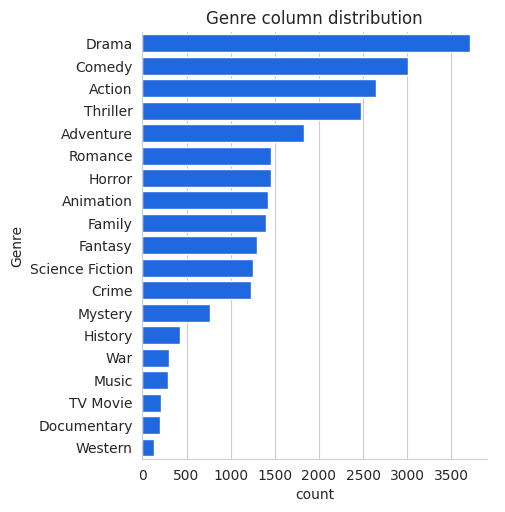

In [50]:
sns.catplot(y=df['Genre'],data=df, kind='count', order=df['Genre'].value_counts().index, color='#0060FF')
plt.title('Genre column distribution')
plt.show()

#Highest votes in the vote average column

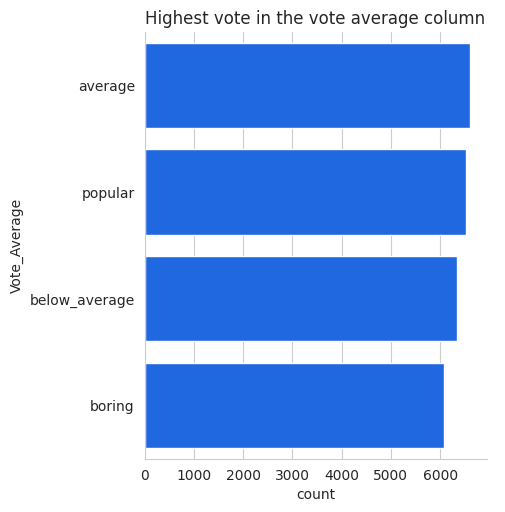

In [53]:
sns.catplot(data=df , y = df['Vote_Average'], kind='count',
order=df['Vote_Average'].value_counts().index, color='#0060FF')

plt.title('Highest vote in the vote average column')
plt.show()

#Movie with the lowest and the highest propularity and their genre

##higest

In [74]:
#Sorted the dataframe in decending order of popularity
df.sort_values(by='Popularity', ascending=False).head()

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre
0,2021.0,Spider-Man: No Way Home,5083.954,8940,popular,Action
1,2021.0,Spider-Man: No Way Home,5083.954,8940,popular,Adventure
2,2021.0,Spider-Man: No Way Home,5083.954,8940,popular,Science Fiction
3,2022.0,The Batman,3827.658,1151,popular,Crime
4,2022.0,The Batman,3827.658,1151,popular,Mystery


In [59]:
# Other method
#calling the dataframe with the condition that the movie having the highest popularity is is shown only.
df[df['Popularity'] == df['Popularity'].max()]

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre
0,2021.0,Spider-Man: No Way Home,5083.954,8940,popular,Action
1,2021.0,Spider-Man: No Way Home,5083.954,8940,popular,Adventure
2,2021.0,Spider-Man: No Way Home,5083.954,8940,popular,Science Fiction


##Lowest

In [79]:
#As there are two different movies which have the same popularity therefore adding a tie breaker column which can filter out the most accurate result.
df.sort_values(by=['Popularity','Vote_Count']).head()
# the argument(By) in the sort_values function is given as a list of two columms as a parameter

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre
25545,2021.0,The United States vs. Billie Holiday,13.354,152,average,Music
25546,2021.0,The United States vs. Billie Holiday,13.354,152,average,Drama
25547,2021.0,The United States vs. Billie Holiday,13.354,152,average,History
25548,1984.0,Threads,13.354,186,popular,War
25549,1984.0,Threads,13.354,186,popular,Drama


In [78]:
# other Method
df[df['Popularity'] == df['Popularity'].min()]

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre
25545,2021.0,The United States vs. Billie Holiday,13.354,152,average,Music
25546,2021.0,The United States vs. Billie Holiday,13.354,152,average,Drama
25547,2021.0,The United States vs. Billie Holiday,13.354,152,average,History
25548,1984.0,Threads,13.354,186,popular,War
25549,1984.0,Threads,13.354,186,popular,Drama
25550,1984.0,Threads,13.354,186,popular,Science Fiction


#Year in which the highest number of movies are shooted

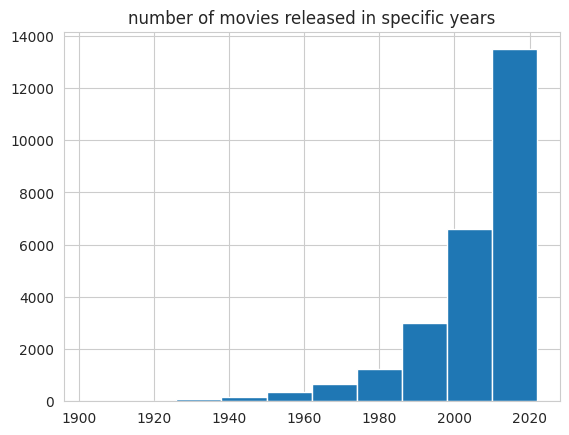

In [80]:
df['Release_Date'].hist()
plt.title('number of movies released in specific years')
plt.show()

#Summary

>Most frequent Genre of Movies Released on Netflix (DRAMA)

>Highest votes in the vote average column (Average movies)

>Movie with the lowest and the highest propularity and their genre(The United States vs. Billie Holiday, Spider-Man: No Way Home)

>Year in which the highest number of movies are shooted (2020)